# ERSST Data: NetCDF to Zarr

The purpose of this notebook is to show the basics of how to work with the xarray data structure and the NetCDF and Zarr file formats.

## Workflow
* Load and inspect the source dataset.
* Extract the California-region subset.
* Write the subset to Zarr.
* Reopen the stored dataset and verify correctness.
* Assemble monthly time-series from 12 monthly NetCDF files.

## Load and inspect the source dataset

The source data are provided in NetCDF format. Use xarray to open the file as a labeled dataset.

Before processing, inspect the dataset structure and confirm the coordinate conventions used for geographic selection.

In [1]:
import xarray as xr
from pathlib import Path

ds = xr.open_dataset("ersst.v5.185401.nc")

ds

<xarray.Dataset> Size: 130kB
Dimensions:  (time: 1, lev: 1, lat: 89, lon: 180)
Coordinates:
  * time     (time) object 8B 1854-01-01 00:00:00
  * lev      (lev) float64 8B 0.0
  * lat      (lat) float64 712B -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
  * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Data variables:
    sst      (time, lev, lat, lon) float32 64kB ...
    ssta     (time, lev, lat, lon) float32 64kB ...
Attributes: (12/38)
    Conventions:                CF-1.6, ACDD-1.3
    metadata_link:              https://doi.org/10.7289/V5T72FNM
    id:                         ersst.v5.185401
    naming_authority:           gov.noaa.ncei
    title:                      NOAA ERSSTv5 (in situ only)
    summary:                    ERSST.v5 is developped based on v4 after revi...
    ...                         ...
    platform:                   Ship and Buoy SSTs from ICOADS R3.0 and NCEP GTS
    instrument:                 Conventional thermometers
    source:                     In situ data: ICOADS R3.0 before 2015, NCEP i...
    comment:                    SSTs were observed by conventional thermomete...
    references:                 Huang et al, 2017: Extended Reconstructed Sea...
    climatology:                Climatology is based on 1971-2000 SST, Xue, Y...

In [2]:
print("Dimensions:")
print(ds.sizes)

print("\nData variables:")
print(list(ds.data_vars))

print("\nCoordinates:")
print(list(ds.coords))

Dimensions:
Frozen({'time': 1, 'lev': 1, 'lat': 89, 'lon': 180})

Data variables:
['sst', 'ssta']

Coordinates:
['lat', 'lev', 'lon', 'time']


## Plot the sea surface temperature variable.

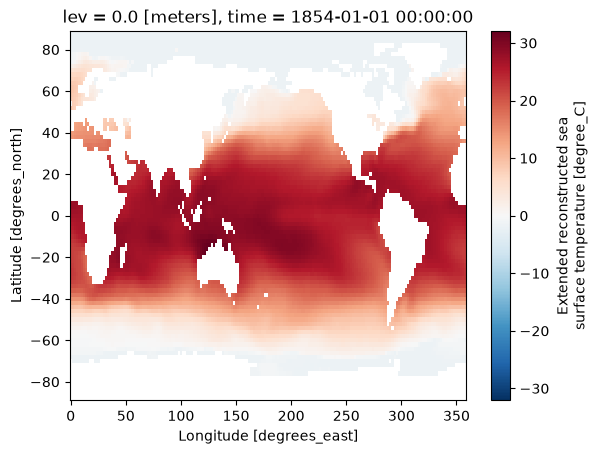

In [3]:
ds['sst'].plot()

## Select California region

Use xarray's sel() and slice() functions to select a subset spanning latitudes 25–45° N and longitudes 225–245°.

In [4]:
region = ds.sel(
    lat=slice(25, 45),
    lon=slice(225, 245),
)

region

<xarray.Dataset> Size: 976B
Dimensions:  (time: 1, lev: 1, lat: 10, lon: 10)
Coordinates:
  * time     (time) object 8B 1854-01-01 00:00:00
  * lev      (lev) float64 8B 0.0
  * lat      (lat) float64 80B 26.0 28.0 30.0 32.0 34.0 36.0 38.0 40.0 42.0 44.0
  * lon      (lon) float64 80B 226.0 228.0 230.0 232.0 ... 240.0 242.0 244.0
Data variables:
    sst      (time, lev, lat, lon) float32 400B ...
    ssta     (time, lev, lat, lon) float32 400B ...
Attributes: (12/38)
    Conventions:                CF-1.6, ACDD-1.3
    metadata_link:              https://doi.org/10.7289/V5T72FNM
    id:                         ersst.v5.185401
    naming_authority:           gov.noaa.ncei
    title:                      NOAA ERSSTv5 (in situ only)
    summary:                    ERSST.v5 is developped based on v4 after revi...
    ...                         ...
    platform:                   Ship and Buoy SSTs from ICOADS R3.0 and NCEP GTS
    instrument:                 Conventional thermometers
    source:                     In situ data: ICOADS R3.0 before 2015, NCEP i...
    comment:                    SSTs were observed by conventional thermomete...
    references:                 Huang et al, 2017: Extended Reconstructed Sea...
    climatology:                Climatology is based on 1971-2000 SST, Xue, Y...

## Validate that the selected region is within the lat/lon boundary.

In [5]:
# Validation

assert region.sizes["lat"] > 0
assert region.sizes["lon"] > 0

assert float(region.lat.min()) >= 25
assert float(region.lat.max()) <= 45
assert float(region.lon.min()) >= 225
assert float(region.lon.max()) <= 245

print("Regional selection passed validation.")
print("Dimensions:", dict(region.sizes))

Regional selection passed validation.
Dimensions: {'time': 1, 'lev': 1, 'lat': 10, 'lon': 10}


## Plot sea surface temp for the selected region. 

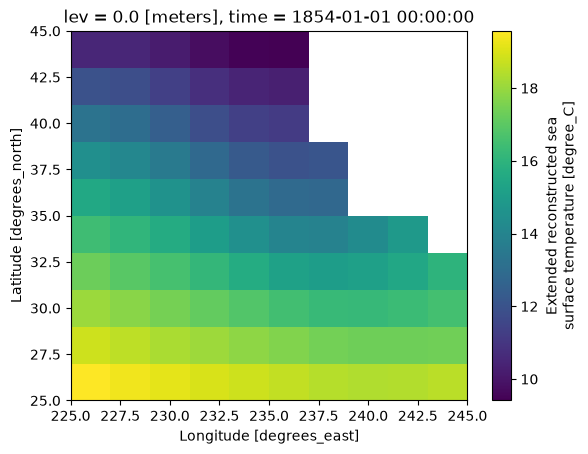

In [6]:
region['sst'].plot()

## Write the regional subset to Zarr

In [7]:
output_path = "ersst_california.zarr"

region.to_zarr(output_path, mode="w", zarr_format=2)

print(f"Zarr dataset written to: {output_path}")

Zarr dataset written to: ersst_california.zarr


## Open the region stored in zarr format using xarray.

Open the zarr region and validate that it is equal to the original NetCDF region.

In [8]:
region_zarr = xr.open_zarr(output_path, zarr_format=2)

xr.testing.assert_equal(region, region_zarr)

print("Zarr round-trip validation passed.")

Zarr round-trip validation passed.


## Plot the zarr-formatted region.

It should be identical to the plot above.

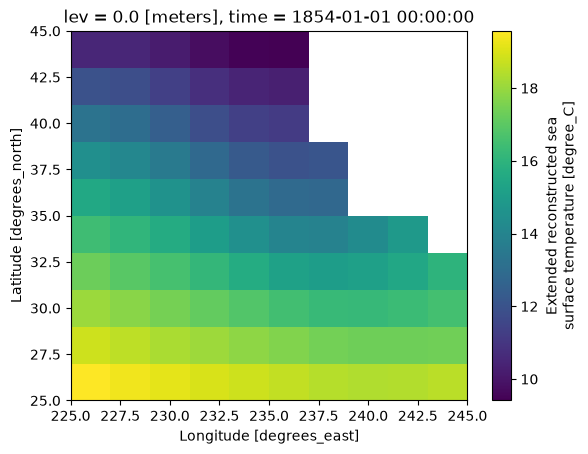

In [9]:
region_zarr['sst'].plot()

## Inspect the Zarr storage layout

Inspect the stored SST array's shape and chunk layout.

In [10]:
sst_zarr = region_zarr["sst"]

print("Array dimensions:", sst_zarr.dims)
print("Array shape:", sst_zarr.shape)
print("Dask chunks:", sst_zarr.chunks)
print("Stored chunk encoding:", sst_zarr.encoding.get("chunks"))

Array dimensions: ('time', 'lev', 'lat', 'lon')
Array shape: (1, 1, 10, 10)
Dask chunks: ((1,), (1,), (10,), (10,))
Stored chunk encoding: (1, 1, 10, 10)


## Assemble a monthly time series

The source data is distributed as individual monthly NetCDF files. Here we combine 12 monthly files along their time dimension to create a dataset representing one year of data.

In [11]:
from pathlib import Path

nc_files = sorted(Path(".").glob("ersst.v5.1854*.nc"))

ds_year = xr.open_mfdataset(nc_files, combine="by_coords", parallel=False)

ds_year

<xarray.Dataset> Size: 2MB
Dimensions:  (time: 12, lev: 1, lat: 89, lon: 180)
Coordinates:
  * time     (time) object 96B 1854-01-01 00:00:00 ... 1854-12-01 00:00:00
  * lev      (lev) float64 8B 0.0
  * lat      (lat) float64 712B -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
  * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Data variables:
    sst      (time, lev, lat, lon) float32 769kB dask.array<chunksize=(1, 1, 89, 180), meta=np.ndarray>
    ssta     (time, lev, lat, lon) float32 769kB dask.array<chunksize=(1, 1, 89, 180), meta=np.ndarray>
Attributes: (12/38)
    Conventions:                CF-1.6, ACDD-1.3
    metadata_link:              https://doi.org/10.7289/V5T72FNM
    id:                         ersst.v5.185401
    naming_authority:           gov.noaa.ncei
    title:                      NOAA ERSSTv5 (in situ only)
    summary:                    ERSST.v5 is developped based on v4 after revi...
    ...                         ...
    platform:                   Ship and Buoy SSTs from ICOADS R3.0 and NCEP GTS
    instrument:                 Conventional thermometers
    source:                     In situ data: ICOADS R3.0 before 2015, NCEP i...
    comment:                    SSTs were observed by conventional thermomete...
    references:                 Huang et al, 2017: Extended Reconstructed Sea...
    climatology:                Climatology is based on 1971-2000 SST, Xue, Y...

## Select the same California region for the 12-month dataset.

Also, validate the resulting time coordinate to ensure that the dataset contains the expected twelve consecutive monthly observations.

In [12]:
region_year = ds_year.sel(lat=slice(25, 45), lon=slice(225, 245))

print("Dimensions:", dict(region_year.sizes))
print("Time steps:", region_year.sizes["time"])

Dimensions: {'time': 12, 'lev': 1, 'lat': 10, 'lon': 10}
Time steps: 12


## Store the regional time series in Zarr

Write the twelve-month California-region dataset to a separate Zarr store.

In [13]:
output_year_path = "ersst_california_1854.zarr"

region_year.to_zarr(output_year_path, mode="w", zarr_format=2)

print(f"Wrote regional time series to {output_year_path}")

Wrote regional time series to ersst_california_1854.zarr


## Open the zarr data and validate.

In [14]:
region_year_zarr = xr.open_zarr(output_year_path, zarr_format=2)

xr.testing.assert_equal(region_year, region_year_zarr)

print("12-month Zarr round-trip validation passed.")

12-month Zarr round-trip validation passed.


## Inspect the time-series storage layout

In [15]:
sst_year = region_year_zarr["sst"]

print("Dimensions:", sst_year.dims)
print("Shape:", sst_year.shape)
print("Dask chunks:", sst_year.chunks)
print("Stored Zarr chunks:", sst_year.encoding.get("chunks"))

Dimensions: ('time', 'lev', 'lat', 'lon')
Shape: (12, 1, 10, 10)
Dask chunks: ((1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1), (1,), (10,), (10,))
Stored Zarr chunks: (1, 1, 10, 10)


## Compare a single-month spatial query with a time-series query.

In [16]:
sst = region_year_zarr["sst"]

print("Array dimensions:", sst.dims)
print("Array shape:", sst.shape)
print("Stored chunks:", sst.encoding.get("chunks"))

Array dimensions: ('time', 'lev', 'lat', 'lon')
Array shape: (12, 1, 10, 10)
Stored chunks: (1, 1, 10, 10)


In [37]:
# Query A: one month's regional map
monthly_map = sst.isel(time=0, lev=0)

# Query B: one grid cell across all months
point_series = sst.isel(
    lev=0,
    lat=sst.sizes["lat"] // 2,
    lon=sst.sizes["lon"] // 2,
)

print("Monthly map shape:", monthly_map.shape)
print("Time-series shape:", point_series.shape)

Monthly map shape: (10, 10)
Time-series shape: (12,)


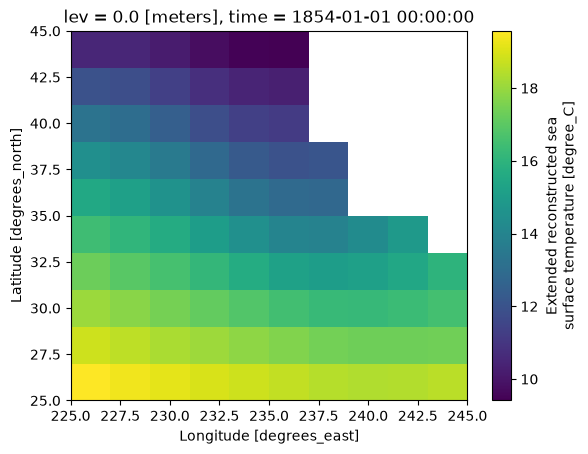

In [18]:
monthly_map.plot()

In [38]:
print(f'mean temp: {monthly_map.mean().compute().item()}')

mean temp: 15.049182609275535


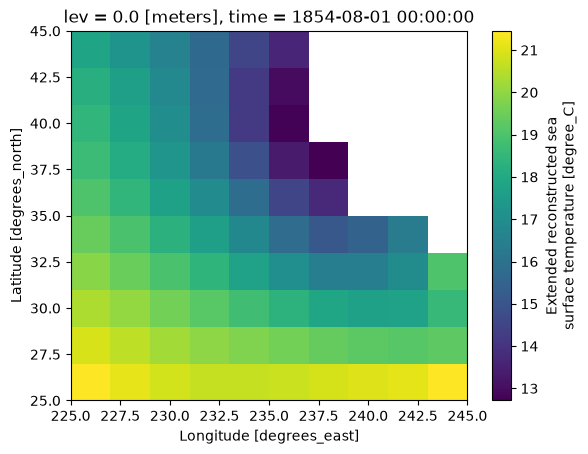

In [34]:
monthly_map_2 = sst.isel(time=7, lev=0)
monthly_map_2.plot()

In [39]:
print(f'mean temp: {monthly_map_2.mean().compute().item()}')

mean temp: 17.83210790893178
